# E0 carbonate consistency, and E1

This script Uses our E0 re-runs, which save the full carbonate state per depth node and timestep.

1. Validate our carbonate port
2. E0 reproduces the published results
3. Is E0 carbonate-consistent?
4. E1: E0 dissolution, consistent speciation

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, matplotlib.pyplot as plt, matplotlib as mpl
from beerling_analysis import io, mixing, experiments as X, carbonate as carb

mpl.rcParams.update({"font.size": 10, "figure.dpi": 120, "axes.grid": False})
OI = dict(blue="#0072B2", vermillion="#D55E00", green="#009E73",
          orange="#E69F00", purple="#CC79A7", sky="#56B4E9", grey="0.45")

SITES = io.SITES
RUNS = {(d, c): X.Run(io.load_run(d, c)) for d in SITES for c in (1, 2)}
_, index = io.load_drivers()
print(f"{len(RUNS)} runs loaded")
for d, s in SITES.items():
    r = RUNS[(d, 1)]
    print(f"  drv{d:<4d} {s['crop']:<13s} {s['where']:<10s} <- {s['state']:<15s} "
          f"{s['years']:2d} yr  {r.pH.shape[1]:5d} steps  buffer={r.buffer}")

12 runs loaded
  drv6    Maize         Missouri   <- Virginia        28 yr   2801 steps  buffer=yes
  drv390  Maize         Indiana    <- North_Carolina  28 yr   2801 steps  buffer=yes
  drv214  Maize         Iowa       <- Minnesota       36 yr   3601 steps  buffer=yes
  drv276  Spring wheat  Montana    <- Oregon          15 yr   1501 steps  buffer=yes
  drv180  Spring wheat  Minnesota  <- Minnesota       45 yr   4501 steps  buffer=yes
  drv162  Soy           Illinois   <- Wisconsin       25 yr   2501 steps  buffer=yes


---
# 1. Validation

Compare `beerling_analysis.carbonate` against the model's carbonate solver, using the constants from `Ca_sat_not_buffered.m`.

### 1.1 Compare to b25's `CaSat*_data.mat` tables

In [2]:
import scipy.io as sio
UP = ("/Users/tylerkukla/Github/b25-model-extension/upstream/"
      "weathering_model/particle_weathering_300123/")

for name, buffered in (("CaSatNotBuffered_data.mat", False), ("CaSatBuffered_data.mat", True)):
    d = sio.loadmat(UP + name, squeeze_me=True)
    CO2, dA, V = d["CO2"].astype(float), d["delAlk"].astype(float), d["values"]
    ci = np.linspace(0, len(CO2) - 1, 16).astype(int)
    ai = np.linspace(0, len(dA) - 1, 500).astype(int)
    CC, AA = np.meshgrid(CO2[ci], dA[ai], indexing="ij")
    ours, theirs = carb.ca_sat(CC, AA, buffered=buffered), V[np.ix_(ci, ai)]
    ok = theirs > 1e-9
    rel = np.abs(ours[ok] - theirs[ok]) / theirs[ok]
    print(f"{'buffered' if buffered else 'thermodynamic':>14s}  n={ok.sum():5d}   "
          f"max rel err {rel.max():.2e}   median {np.median(rel):.2e}")

 thermodynamic  n= 8000   max rel err 6.28e-08   median 5.98e-10
      buffered  n= 6120   max rel err 2.49e-01   median 6.00e-10


The thermodynamic branch (used by E1) matches to ~6 × 10⁻⁸. The buffered branch is looser: outside pH $(1, 1+a)$ MATLAB takes a complex log, which we mimic with $\log|x|$.

### 1.2 Against each run's saved `Ca_sat`

In [3]:
rows = []
for (d, c), r in RUNS.items():
    ours, theirs = X.recompute_ca_sat(r, buffered=True), r.Ca_sat
    m = theirs > 1e-9
    rel = np.abs(ours[m] - theirs[m]) / theirs[m]
    big = rel > 0.01
    rows.append((d, c, m.sum(), np.median(rel), 100 * big.mean(),
                 theirs[m][big].max() if big.any() else np.nan, r.Ca_sol.max()))

print(f"{'drv':>5} {'cl':>3} {'n':>8} {'median rel':>11} {'>1% of pts':>11} "
      f"{'Ca_sat there':>13} {'Ca_sol max':>11}")
for d, c, n, med, pct, csat, csol in rows:
    print(f"{d:5d} {c:3d} {n:8d} {med:11.2e} {pct:10.2f}% {csat:13.2e} {csol:11.2e}")

  drv  cl        n  median rel  >1% of pts  Ca_sat there  Ca_sol max
    6   1    86800    1.61e-05       0.00%           nan    9.62e-03
    6   2    86800    1.57e-05       0.00%           nan    9.59e-03
  390   1    86327    2.54e-05       0.24%      2.31e-06    7.41e-03
  390   2    86800    2.38e-05       0.01%      1.34e-06    7.40e-03
  214   1   111600    1.74e-05       0.00%           nan    8.97e-03
  214   2   111600    1.75e-05       0.00%           nan    9.02e-03
  276   1    44048    9.82e-05       1.12%      4.68e-06    3.33e-03
  276   2    44530    9.47e-05       0.93%      4.94e-06    3.13e-03
  180   1   139500    2.79e-05       0.00%           nan    9.51e-03
  180   2   139496    2.89e-05       0.01%      1.83e-06    9.48e-03
  162   1    77500    2.74e-05       0.00%           nan    7.24e-03
  162   2    77500    2.33e-05       0.00%           nan    9.74e-03


Median agreement ~10⁻⁵–10⁻⁴. The ≤1% of points off by >1% all have `Ca_sat` ~10³× below dissolved Ca, where calcite precipitates either way.

### 1.3 Ω at the model's own ceiling (should be 1)

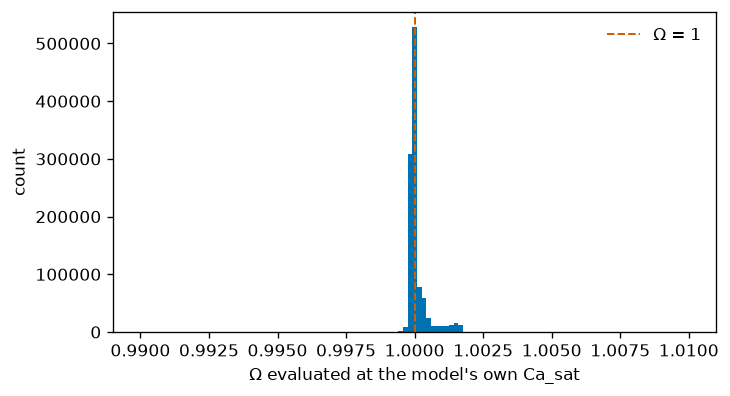

n = 1,092,501 node-timesteps across all 12 runs
median Ω = 0.999966   5-95%: 0.99985 - 1.00103


In [4]:
fig, ax = plt.subplots(figsize=(6.2, 3.4))
allom = []
for r in RUNS.values():
    om = carb.omega(r.Ca_sat, carb.buffered_pH(r.del_alk + 2 * r.Ca_sat, r.soil_co2), r.soil_co2)
    allom.append(om[(r.Ca_sat > 1e-9) & np.isfinite(om)])
allom = np.concatenate(allom)
ax.hist(allom, bins=np.linspace(0.99, 1.01, 120), color=OI["blue"])
ax.axvline(1.0, color=OI["vermillion"], lw=1.2, ls="--", label="Ω = 1")
ax.set_xlabel("Ω evaluated at the model's own Ca_sat"); ax.set_ylabel("count")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

print(f"n = {len(allom):,} node-timesteps across all 12 runs")
print(f"median Ω = {np.median(allom):.6f}   5-95%: "
      f"{np.percentile(allom, 5):.5f} - {np.percentile(allom, 95):.5f}")

Ω = 1.0000: the same carbonate system. Suggests that a gap below is in the alkalinity–pH relation, not the thermodynamics.

### 1.4 Buffered pH and Ca export against the model

In [5]:
print(f"{'drv':>5} {'cl':>3} {'median |dpH|':>13} {'max |dpH|':>10} "
      f"{'export ratio (ours/model)':>26}")
for (d, c), r in RUNS.items():
    dph = np.abs(carb.buffered_pH(r.alk_total, r.soil_co2) - r.pH)
    ours_exp = r.export_mol_per_m2(r.Ca_sol[-1, :])[-1]
    theirs_exp = np.atleast_1d(r.mat["totals"].Outflow.Ca).astype(float)[-1]
    print(f"{d:5d} {c:3d} {np.median(dph):13.2e} {dph.max():10.2e} "
          f"{ours_exp/theirs_exp:26.4f}")

  drv  cl  median |dpH|  max |dpH|  export ratio (ours/model)
    6   1      5.32e-05   7.68e-01                     0.9992
    6   2      5.25e-05   7.68e-01                     0.9990
  390   1      6.22e-05   2.29e-01                     0.9997
  390   2      6.11e-05   2.29e-01                     0.9993
  214   1      5.73e-05   6.49e-01                     0.9994
  214   2      5.79e-05   6.49e-01                     0.9988
  276   1      2.12e-04   8.00e-01                     1.0085
  276   2      2.06e-04   8.00e-01                     1.0034
  180   1      9.74e-05   6.80e-01                     1.0005
  180   2      9.28e-05   6.80e-01                     1.0000
  162   1      6.80e-05   2.38e-01                     0.9997
  162   2      6.64e-05   2.38e-01                     0.9994


pH matches to ~10⁻⁴ (median). Our export integration is within 1% of the model's, so E1 applies it as a ratio to the model's own outflow.

### 1.5 pH against the published series

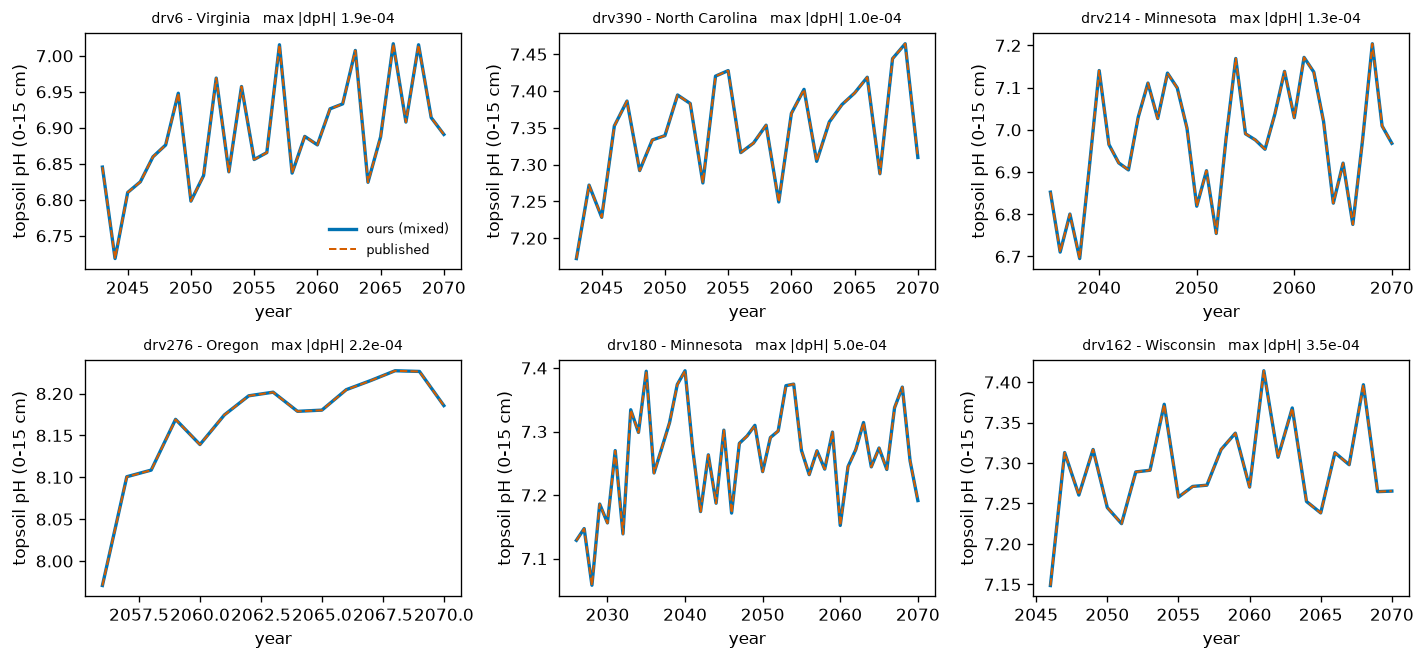

worst |dpH| across all six sites: 5.00e-04 pH units


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.6))
errs = []
for ax, (d, s) in zip(axes.ravel(), SITES.items()):
    ph = []
    for c in (1, 2):
        P = np.atleast_2d(RUNS[(d, c)].mat["pH"]).astype(float).mean(0)  # 0-15 cm mean
        ph.append(P[: len(P) // 12 * 12].reshape(-1, 12).mean(1))       # annual
    w = mixing.weight(s["state"])
    mixed = w * ph[0] + (1 - w) * ph[1]
    yrs, pub = io.published_series("pH", d, s["state"], s["start"], index=index)
    m = (yrs >= s["start"]) & (yrs < s["start"] + s["years"])
    n = min(m.sum(), len(mixed))
    yy, pub, mixed = yrs[m][:n], pub[m][:n], mixed[:n]
    ax.plot(yy, mixed, color=OI["blue"], lw=2, label="ours (mixed)")
    ax.plot(yy, pub, color=OI["vermillion"], lw=1.2, ls="--", label="published")
    errs.append(np.abs(mixed - pub).max())
    ax.set_title(f"drv{d} - {s['state'].replace('_',' ')}   max |dpH| {errs[-1]:.1e}", fontsize=8.5)
    ax.set_xlabel("year"); ax.set_ylabel("topsoil pH (0-15 cm)")
axes.ravel()[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print(f"worst |dpH| across all six sites: {max(errs):.2e} pH units")

---
# 2. E0 reproduces the published results

Published `N2` $= w\,r_1 + (1-w)\,r_2$ over the two mineralogy-cluster runs, with $w$ from Extended Data Fig. 3a (`data/mineralogy_cluster_counts.csv`).

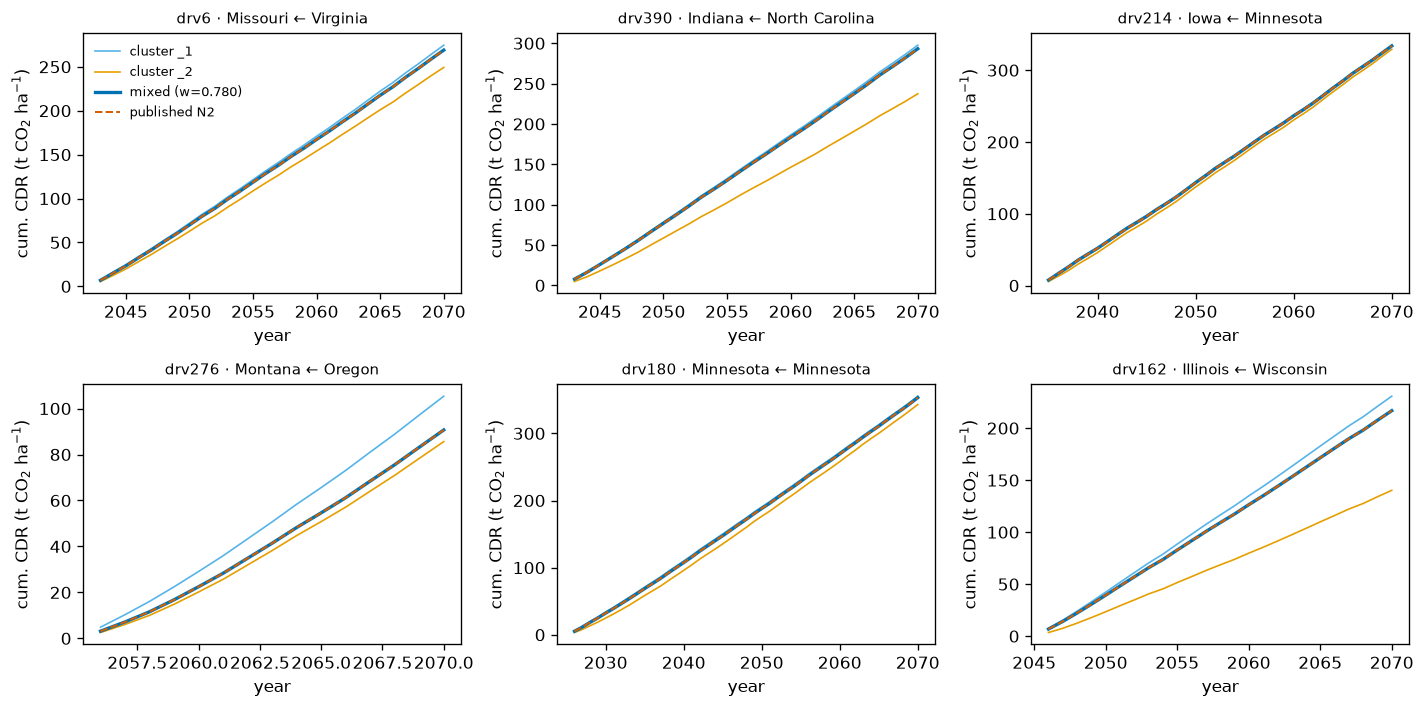

  drv           source         w   max err vs published N2
    6         Virginia  0.779817                   0.0009%
  390   North Carolina  0.927114                   0.0033%
  214        Minnesota  0.829545                   0.0004%
  276           Oregon  0.256840                   0.0007%
  180        Minnesota  0.829545                   0.0091%
  162        Wisconsin  0.846154                   0.0006%


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
summary = []
for ax, (d, s) in zip(axes.ravel(), SITES.items()):
    yrs, pub = io.published_series("CO2", d, s["state"], s["start"], index=index)
    m = (yrs >= s["start"]) & (yrs < s["start"] + s["years"])
    yy, pubc = yrs[m], np.cumsum(pub[m])
    a, b = (np.atleast_1d(RUNS[(d, c)].mat["CO2_mass"]).astype(float)[12::12][:m.sum()]
            * io.G_PER_M2_TO_T_PER_HA for c in (1, 2))  # monthly -> year ends
    w = mixing.weight(s["state"]); mixed = w * a + (1 - w) * b
    ax.plot(yy, a, color=OI["sky"], lw=1, label="cluster _1")
    ax.plot(yy, b, color=OI["orange"], lw=1, label="cluster _2")
    ax.plot(yy, mixed, color=OI["blue"], lw=2, label=f"mixed (w={w:.3f})")
    ax.plot(yy, pubc, color=OI["vermillion"], lw=1.2, ls="--", label="published N2")
    ax.set_title(f"drv{d} · {s['where']} ← {s['state'].replace('_',' ')}", fontsize=9)
    ax.set_xlabel("year"); ax.set_ylabel("cum. CDR (t CO$_2$ ha$^{-1}$)")
    summary.append((d, s["state"], w, 100 * (np.abs(mixed - pubc) / pubc).max()))
axes.ravel()[0].legend(frameon=False, fontsize=7.5)
plt.tight_layout(); plt.show()

print(f"{'drv':>5} {'source':>16} {'w':>9} {'max err vs published N2':>25}")
for d, st, w, e in summary:
    print(f"{d:5d} {st.replace('_',' '):>16} {w:9.6f} {e:24.4f}%")

All six sites match to < 0.01%.

---
# 3. Is E0 carbonate-consistent?

Ω at the model's own Ca, alkalinity and soil pCO₂, under carbonate equilibrium.

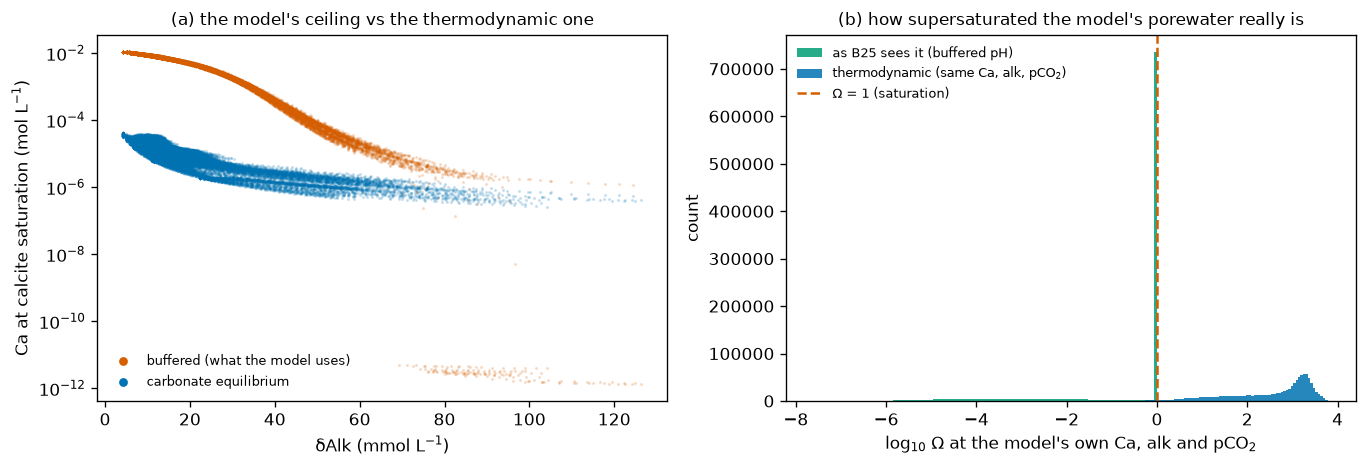

Ω under carbonate equilibrium:  p5 4.3   p25 83.6   p50 823.2   p75 1794.9   p95 3260.6   frac > 1: 0.986
Ω with the model's buffered pH: median 0.9999   p95 1.0003   frac > 1: 0.183


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))

ax = axes[0]
for (d, c), r in RUNS.items():
    if c != 1: continue
    sub = (slice(None), slice(0, None, 25))
    dA, co2 = r.del_alk[sub].ravel(), r.soil_co2[sub].ravel()
    g = (co2 > 0) & (dA > 0)
    ax.scatter(dA[g] * 1e3, r.Ca_sat[sub].ravel()[g], s=1, alpha=.15, color=OI["vermillion"])
    ax.scatter(dA[g] * 1e3, carb.ca_sat(co2[g], dA[g], buffered=False), s=1, alpha=.15,
               color=OI["blue"])
ax.set_yscale("log"); ax.set_xlabel("δAlk (mmol L$^{-1}$)")
ax.set_ylabel("Ca at calcite saturation (mol L$^{-1}$)")
ax.set_title("(a) the model's ceiling vs the thermodynamic one", fontsize=10)
ax.scatter([], [], s=18, color=OI["vermillion"], label="buffered (what the model uses)")
ax.scatter([], [], s=18, color=OI["blue"], label="carbonate equilibrium")
ax.legend(frameon=False, fontsize=8, loc="lower left")

ax = axes[1]
oms, oms_model = [], []
for r in RUNS.values():
    for out, ph in ((oms, carb.alk_to_pH(r.alk_total, r.soil_co2)),
                    (oms_model, carb.buffered_pH(r.alk_total, r.soil_co2))):
        om = carb.omega(r.Ca_sol, ph, r.soil_co2)
        out.append(om[(r.Ca_sol > 1e-9) & np.isfinite(om) & (om > 0)])
oms, oms_model = np.concatenate(oms), np.concatenate(oms_model)
ax.hist(np.log10(oms_model), bins=120, color=OI["green"], alpha=.85,
        label="as B25 sees it (buffered pH)")
ax.hist(np.log10(oms), bins=120, color=OI["blue"], alpha=.85,
        label="thermodynamic (same Ca, alk, pCO$_2$)")
ax.axvline(0, color=OI["vermillion"], lw=1.5, ls="--", label="Ω = 1 (saturation)")
ax.set_xlabel("log$_{10}$ Ω at the model's own Ca, alk and pCO$_2$")
ax.set_ylabel("count"); ax.legend(frameon=False, fontsize=7.5)
ax.set_title("(b) how supersaturated the model's porewater really is", fontsize=10)
plt.tight_layout(); plt.show()

print("Ω under carbonate equilibrium:  "
      + "   ".join(f"p{p} {np.percentile(oms, p):.1f}" for p in (5, 25, 50, 75, 95))
      + f"   frac > 1: {np.mean(oms > 1):.3f}")
print(f"Ω with the model's buffered pH: median {np.median(oms_model):.4f}   "
      f"p95 {np.percentile(oms_model, 95):.4f}   frac > 1: {np.mean(oms_model > 1):.3f}")

Under equilibrium the porewater is supersaturated ~800× (median Ω); with its own buffered pH the model sees Ω ≈ 1. Panel (a): the buffered ceiling sits far above the thermodynamic one, so Ca that should precipitate appears to be exported instead.

### 3.1 Comparing versus soil-CO2

The soil pCO2 that would reconcile the model's own pH and alkalinity:

$$p\mathrm{CO_2^{req}} = \frac{\mathrm{Alk} - K_w/[\mathrm{H^+}] + [\mathrm{H^+}]}{K_h \rho\,(\alpha_1 + 2\alpha_2)/\alpha_0}$$

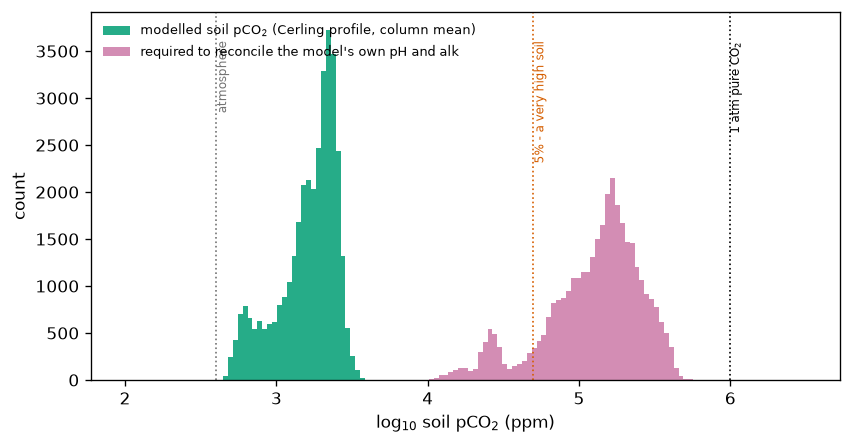

column-mean soil pCO2, all sites and timesteps (n=35,400):
  modelled : median     1828 ppm  (0.18%)
  required : median   144687 ppm  (14.5%)
  ratio    : median 89x   p95 235x
  required > 5% CO2 at 88% of points


In [10]:
mod_all, req_all = [], []
for r in RUNS.values():
    H = 10.0 ** -carb.buffered_pH(r.alk_total, r.soil_co2)
    num = r.alk_total - carb.KW / H + H
    req = num / (carb.KH * carb.RHO * (carb._a1(H) + 2 * carb._a2(H)) / carb._a0(H))
    g = (r.soil_co2 > 0) & np.isfinite(req) & (req > 0)
    mod_all.append(np.mean(np.where(g, r.soil_co2, np.nan), axis=0))
    req_all.append(np.nanmean(np.where(g, req, np.nan), axis=0))
mod_all, req_all = np.concatenate(mod_all), np.concatenate(req_all)
ok = np.isfinite(mod_all) & np.isfinite(req_all)
mod_all, req_all = mod_all[ok], req_all[ok]

fig, ax = plt.subplots(figsize=(7.2, 3.8))
bins = np.linspace(2, 6.5, 140)
ax.hist(np.log10(mod_all), bins=bins, color=OI["green"], alpha=.85,
        label="modelled soil pCO$_2$ (Cerling profile, column mean)")
ax.hist(np.log10(req_all), bins=bins, color=OI["purple"], alpha=.85,
        label="required to reconcile the model's own pH and alk")
for v, lab, col in ((np.log10(4e2), "atmosphere", OI["grey"]),
                    (np.log10(5e4), "5% - a very high soil", OI["vermillion"]),
                    (6.0, "1 atm pure CO$_2$", "k")):
    ax.axvline(v, color=col, lw=1, ls=":")
    ax.text(v, ax.get_ylim()[1] * 0.92, " " + lab, fontsize=7, color=col, rotation=90, va="top")
ax.set_xlabel("log$_{10}$ soil pCO$_2$ (ppm)"); ax.set_ylabel("count")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

ratio = req_all / mod_all
print(f"column-mean soil pCO2, all sites and timesteps (n={len(mod_all):,}):")
print(f"  modelled : median {np.median(mod_all):8.0f} ppm  ({np.median(mod_all)/1e4:.2f}%)")
print(f"  required : median {np.median(req_all):8.0f} ppm  ({np.median(req_all)/1e4:.1f}%)")
print(f"  ratio    : median {np.median(ratio):.0f}x   p95 {np.percentile(ratio, 95):.0f}x")
print(f"  required > 5% CO2 at {np.mean(req_all > 5e4):.0%} of points")

---
# 4. E1: E0 dissolution, consistent speciation

E1/E0 isolates the export effect. 

In [11]:
res = {d: X.e1(RUNS[(d, 1)]) for d in SITES}
res2 = {d: X.e1(RUNS[(d, 2)]) for d in SITES}

def mix(d, key):
    w = mixing.weight(SITES[d]["state"])
    return w * res[d][key][-1] + (1 - w) * res2[d][key][-1]

print(f"{'drv':>5} {'source':>16} {'E0 CDR':>9} {'E1 CDR':>9} {'retained':>9} "
      f"{'E0 SIC%':>8} {'E1 SIC%':>8}")
ret = []
for d, s in SITES.items():
    e0, e1, s0, s1 = (mix(d, k) for k in ("cdr_e0_t_ha", "cdr_e1_t_ha", "sic_e0_t_ha", "sic_e1_t_ha"))
    ret.append(e1 / e0)
    print(f"{d:5d} {s['state'].replace('_',' '):>16} {e0:9.2f} {e1:9.2f} "
          f"{e1/e0:9.1%} {s0/e0:8.1%} {s1/e1:8.1%}")
print(f"\nretained: {min(ret):.1%} - {max(ret):.1%} (median {np.median(ret):.1%})")

  drv           source    E0 CDR    E1 CDR  retained  E0 SIC%  E1 SIC%
    6         Virginia    268.98    220.23     81.9%    12.2%    46.0%
  390   North Carolina    293.20    266.55     90.9%    22.4%    38.7%
  214        Minnesota    333.85    285.02     85.4%    15.0%    41.6%
  276           Oregon     90.69     90.68    100.0%    47.4%    47.5%
  180        Minnesota    353.26    335.16     94.9%    33.6%    43.0%
  162        Wisconsin    216.78    197.46     91.1%    30.1%    46.9%

retained: 81.9% - 100.0% (median 91.0%)


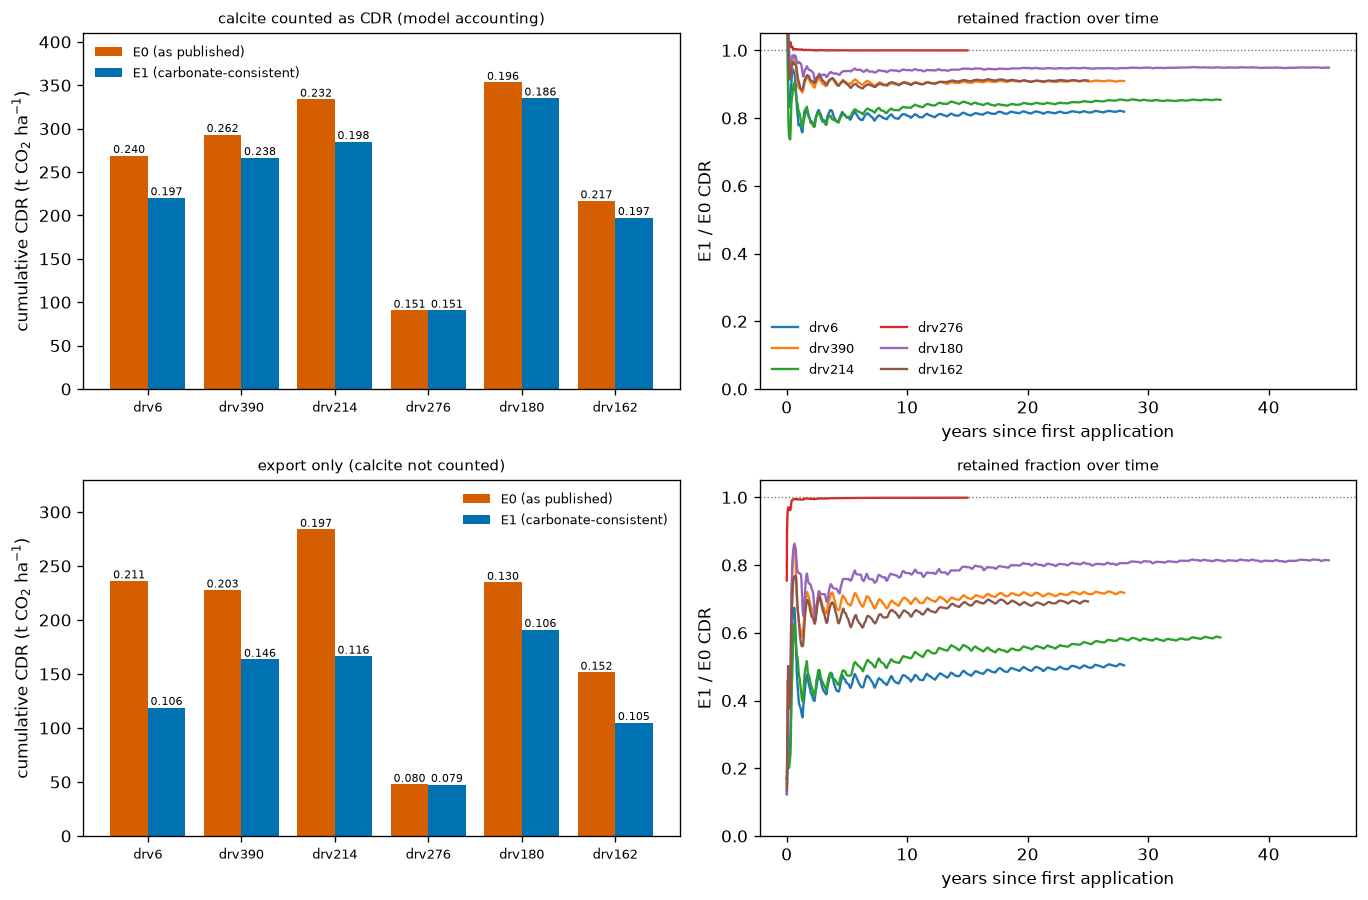

bar labels: t CO2 per t rock
  drv  SIC counts: E0       E1    ret |  export only: E0       E1    ret
    6           269.0    220.2    82% |            236.1    119.0    50%
  390           293.2    266.6    91% |            227.7    163.5    72%
  214           333.9    285.0    85% |            283.8    166.4    59%
  276            90.7     90.7   100% |             47.7     47.6   100%
  180           353.3    335.2    95% |            234.7    191.1    81%
  162           216.8    197.5    91% |            151.5    104.9    69%


In [12]:
def cdr_curves(d, count_sic):
    "Mixed (E0, E1) cumulative CDR; count_sic=False drops the calcite credit (mass_balance.m:233)."
    w = mixing.weight(SITES[d]["state"])
    out = []
    for c, rr in ((1, res[d]), (2, res2[d])):
        if count_sic:
            out.append((rr["cdr_e0_t_ha"], rr["cdr_e1_t_ha"]))
            continue
        o = RUNS[(d, c)].mat["totals"].Outflow
        ca, mg, k, na = (np.atleast_1d(getattr(o, f)).astype(float) for f in ("Ca", "Mg", "K", "Na"))
        out.append(tuple(rr["eta"] * (na + k + 2 * (mg + ca * f)) * 44 * 0.01
                         for f in (1, rr["ca_export_ratio"])))
    return tuple(w * a + (1 - w) * b for a, b in zip(*out))

curves = {(d, sic): cdr_curves(d, sic) for d in SITES for sic in (True, False)}
ROCK = {d: np.atleast_1d(RUNS[(d, 1)].mat["Application_Basalt_mass"]).astype(float)[-1] * 0.01
        for d in SITES}

fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.6))
xp = np.arange(len(SITES))
for row, (sic, title) in enumerate([(True, "calcite counted as CDR (model accounting)"),
                                    (False, "export only (calcite not counted)")]):
    ax = axes[row, 0]
    for i, dx, col, lab in ((0, -.2, OI["vermillion"], "E0 (as published)"),
                            (1, .2, OI["blue"], "E1 (carbonate-consistent)")):
        v = [curves[(d, sic)][i][-1] for d in SITES]
        ax.bar(xp + dx, v, .4, color=col, label=lab)
        for x, y, d in zip(xp + dx, v, SITES):
            ax.text(x, y, f"{y / ROCK[d]:.3f}", ha="center", va="bottom", fontsize=6.5)
    ax.set_xticks(xp); ax.set_xticklabels([f"drv{d}" for d in SITES], fontsize=8)
    ax.set_ylabel("cumulative CDR (t CO$_2$ ha$^{-1}$)")
    ax.set_title(title, fontsize=9); ax.legend(frameon=False, fontsize=8); ax.margins(y=.16)

    ax = axes[row, 1]
    for d in SITES:
        e0, e1 = curves[(d, sic)]
        with np.errstate(invalid="ignore", divide="ignore"):
            ax.plot(RUNS[(d, 1)].t, np.where(e0 > 0, e1 / e0, np.nan), lw=1.4, label=f"drv{d}")
    ax.axhline(1, color=OI["grey"], lw=.8, ls=":")
    ax.set_xlabel("years since first application"); ax.set_ylabel("E1 / E0 CDR")
    ax.set_ylim(0, 1.05); ax.set_title("retained fraction over time", fontsize=9)
    if row == 0: ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

print("bar labels: t CO2 per t rock")
print(f"{'drv':>5} {'SIC counts: E0':>15} {'E1':>8} {'ret':>6} | "
      f"{'export only: E0':>16} {'E1':>8} {'ret':>6}")
for d in SITES:
    (a0, a1), (b0, b1) = curves[(d, True)], curves[(d, False)]
    print(f"{d:5d} {a0[-1]:15.1f} {a1[-1]:8.1f} {a1[-1]/a0[-1]:6.0%} | "
          f"{b0[-1]:16.1f} {b1[-1]:8.1f} {b1[-1]/b0[-1]:6.0%}")

### 4.1 Porewater pH

Beerling et al. report a modest topsoil pH rise (Fig. 3a: +0.5–1 unit; ED Fig. 7: mostly < 7.5). That pH comes from the empirical buffer, so this looks at what the same alkalinity implies under carbonate equilibrium?

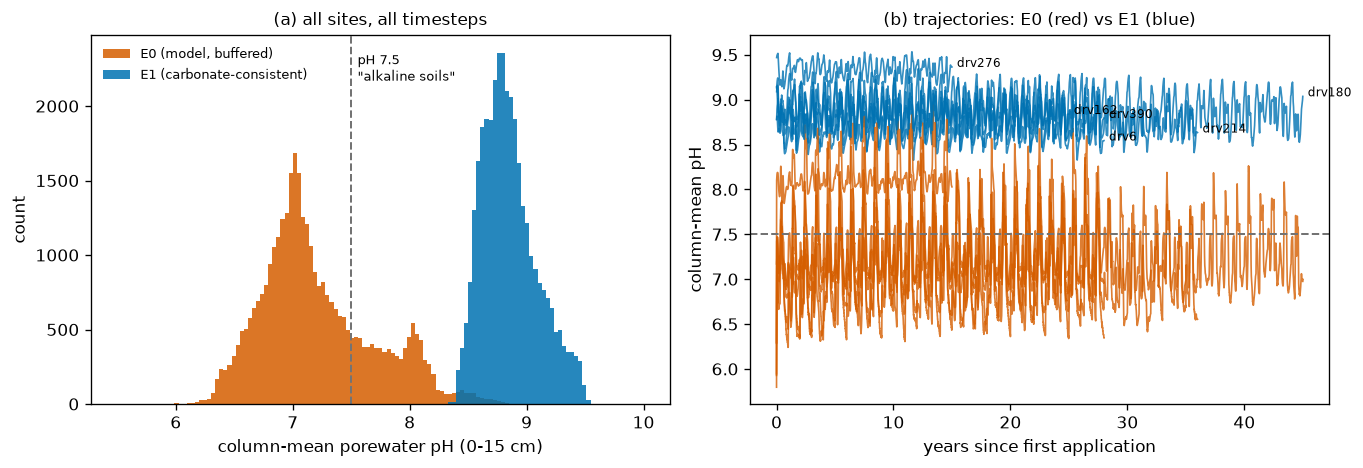

column-mean porewater pH, all sites and timesteps
  E0 (model)     : median 7.10   p95 8.12   above 7.5: 25%
  E1 (consistent): median 8.82   p95 9.31   above 7.5: 100%
  median shift: +1.72 pH units


In [15]:
ph_e1 = {}
for (d, c), r in RUNS.items():
    rr = res[d] if c == 1 else res2[d]
    ph = carb.alk_to_pH(r.del_alk + 2 * rr["Ca_sol_e1"], r.soil_co2)
    ph_e1[(d, c)] = np.nanmean(np.where(r.soil_co2 > 0, ph, np.nan), axis=0)
e0_all = np.concatenate([r.pH_avg[1:] for r in RUNS.values()])
e1_all = np.concatenate([p[1:] for p in ph_e1.values()])
e0_all, e1_all = e0_all[np.isfinite(e0_all)], e1_all[np.isfinite(e1_all)]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
ax = axes[0]
bins = np.linspace(5.5, 10, 130)
ax.hist(e0_all, bins=bins, color=OI["vermillion"], alpha=.85, label="E0 (model, buffered)")
ax.hist(e1_all, bins=bins, color=OI["blue"], alpha=.85, label="E1 (carbonate-consistent)")
ax.axvline(7.5, color=OI["grey"], lw=1.2, ls="--")
ax.text(7.52, ax.get_ylim()[1] * .95, ' pH 7.5\n "alkaline soils"', fontsize=7.5, va="top")
ax.set_xlabel("column-mean porewater pH (0-15 cm)"); ax.set_ylabel("count")
ax.legend(frameon=False, fontsize=8); ax.set_title("(a) all sites, all timesteps", fontsize=10)

ax = axes[1]
for d in SITES:
    r, p = RUNS[(d, 1)], ph_e1[(d, 1)]
    ax.plot(r.t, r.pH_avg, color=OI["vermillion"], lw=1, alpha=.8)
    ax.plot(r.t, p, color=OI["blue"], lw=1, alpha=.8)
    ax.annotate(f"drv{d}", (r.t[-1], p[-1]), fontsize=7, textcoords="offset points", xytext=(3, 0))
ax.axhline(7.5, color=OI["grey"], lw=1.2, ls="--")
ax.set_xlabel("years since first application"); ax.set_ylabel("column-mean pH")
ax.set_title("(b) trajectories: E0 (red) vs E1 (blue)", fontsize=10)
plt.tight_layout(); plt.show()

print("column-mean porewater pH, all sites and timesteps")
for lab, x in (("E0 (model)", e0_all), ("E1 (consistent)", e1_all)):
    print(f"  {lab:<15s}: median {np.median(x):.2f}   p95 {np.percentile(x, 95):.2f}   "
          f"above 7.5: {np.mean(x > 7.5):.0%}")
print(f"  median shift: {np.median(e1_all) - np.median(e0_all):+.2f} pH units")